# Model tuning and development analysis

This notebook compares fixed-setting models with a bounded nested chronological tuning study. The dataset, hourly policy, 100 ms latency, uncapped sizing and partial-fill accounting remain unchanged. Top five is primary; top three is a sensitivity. The final test is unopened.

See `docs/reports/model_tuning.md` for the interpretation. All model logic lives in `src/models/tuning.py`; replay uses the existing simulator.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
import pandas as pd
from IPython.display import display, Image
from threadpoolctl import threadpool_limits
from src.reporting.workflow import profitability_dataset, profitability_run
from src.models.tuning import fit_study
from src.simulator.profitability import replay_profitability
from src.reporting.tuning import build_report, verify_training

DATA = profitability_dataset()
BASELINE = profitability_run()
RUN = BASELINE / 'tuning_study'
RUN_TRAINING = False
RUN_REPLAY = False

if RUN_TRAINING:
    # Set RUN to a fresh directory for a new study; completed runs are immutable.
    with threadpool_limits(limits=4):
        fit_study(RUN, DATA, BASELINE)
completion = verify_training(RUN)
assert completion['final_lockbox_opened'] is False
print('Verified fitted-model and prediction artifacts:', RUN)


Verified fitted-model and prediction artifacts: C:\Users\Daron\coding\inefficiency-prediction\results\profitability\tuning_study


## Tuning protocol

Each of ten model/objective combinations receives eight candidate settings and two inner chronological validation blocks per outer fold. Candidates use combined book and metadata features. Inner training excludes unknown targets and purges the label horizon plus 1.1 seconds. Validation ranking includes every eligible event, including unknown targets.

The selection score is signed standalone top-five P&L per scan, a computational proxy. Persistent replay below determines economic performance. Exact ties choose the first declared candidate. No random time split, early stopping, oversampling or final-test access is used. Two-stage gates fit natural activity prevalence and conditional amounts retain losses.

This is exploratory development after earlier results were inspected, not a new untouched test.

In [2]:
design = json.loads((RUN / 'design.json').read_text())
print(json.dumps(design['packages'], indent=2))
print('Inner selection objective:', design['tuning']['objective'])
selected = pd.read_csv(RUN / 'selected_parameters.csv')
display(selected)
audit = pd.read_csv(RUN / 'fit_audit.csv')
display(audit.groupby('fold').first()[['training_rows', 'train_last_time', 'test_first_time', 'loss_hours']])
warnings = pd.read_csv(RUN / 'warnings.csv')
print('Recorded fit warnings:', len(warnings))


{
  "python": "3.12.6",
  "sklearn": "1.7.2",
  "xgboost": "3.2.0"
}
Inner selection objective: Mean signed standalone selected top-five P&L per inner validation scan; proxy, not persistent replay


,fold,model,candidate,params
0,nov_early,tuned_classifier_logistic,1,"{""C"": 0.01, ""class_weight"": ""balanced"", ""penal..."
1,nov_early,tuned_classifier_random_forest,0,"{""max_depth"": 10, ""max_features"": ""sqrt"", ""min..."
2,nov_early,tuned_classifier_boosted_trees,1,"{""l2_regularization"": 10.0, ""learning_rate"": 0..."
3,nov_early,tuned_classifier_xgboost,3,"{""colsample_bytree"": 0.8, ""learning_rate"": 0.0..."
4,nov_early,tuned_regression_random_forest,1,"{""max_depth"": 4, ""max_features"": 0.5, ""min_sam..."
5,nov_early,tuned_regression_boosted_trees,7,"{""l2_regularization"": 100.0, ""learning_rate"": ..."
6,nov_early,tuned_regression_xgboost,7,"{""colsample_bytree"": 0.8, ""learning_rate"": 0.0..."
7,nov_early,tuned_two_stage_random_forest,6,"{""max_depth"": 6, ""max_features"": 0.5, ""min_sam..."
8,nov_early,tuned_two_stage_boosted_trees,1,"{""l2_regularization"": 10.0, ""learning_rate"": 0..."
9,nov_early,tuned_two_stage_xgboost,0,"{""colsample_bytree"": 1.0, ""learning_rate"": 0.0..."


,training_rows,train_last_time,test_first_time,loss_hours
fold,,,,
dec_late,17690,2025-12-14 22:00:00+00:00,2025-12-15 00:00:00+00:00,11
nov_early,4859,2025-10-31 22:00:00+00:00,2025-11-01 00:00:00+00:00,1
nov_late,11191,2025-11-21 22:00:00+00:00,2025-11-22 00:00:00+00:00,7


Recorded fit warnings: 0


## Persistent replay

The same fitted predictions are replayed at both budgets. Each replay also removes the December Fed event, reranks the remaining events and replays the resulting selections. This exclusion is a concentration sensitivity, not retraining without that event. Saved fixed-setting predictions are copied unchanged for matched benchmarks.

In [3]:
if RUN_REPLAY:
    for budget in (5, 3):
        folder = RUN / f'replay_top{budget}'
        if not (folder / 'run.json').exists():
            if folder.exists():
                raise RuntimeError(f'Incomplete replay: {folder}; use a fresh run directory')
            replay_profitability(folder, DATA, RUN, top_n=budget)
comparison, changes = build_report(RUN)
columns = ['model', 'net_pnl_usd', 'completed_profit_usd', 'partial_pnl_usd',
           'attempts', 'unknown_attempts', 'max_drawdown_usd', 'recall', 'future_recall']
for budget in (5, 3):
    print(f'All events, top {budget}')
    display(comparison.loc[comparison.scope.eq('all_events') & comparison.budget.eq(budget), columns]
            .sort_values('net_pnl_usd', ascending=False).round(4))


All events, top 5


,model,net_pnl_usd,completed_profit_usd,partial_pnl_usd,attempts,unknown_attempts,max_drawdown_usd,recall,future_recall
17,quoted_gap_rule,6045.2515,6328.7206,-283.4690,491,0,142.0794,0.9176,0.8719
28,monitor_all,5951.6045,6366.3507,-414.7462,521,0,205.9126,NaN,NaN
2,combined_random_forest,5942.7078,6357.4540,-414.7462,513,0,205.9126,0.9574,0.9339
21,tuned_classifier_xgboost,5941.9394,6356.6856,-414.7462,512,0,205.9126,0.9548,0.9339
20,tuned_classifier_random_forest,5940.0580,6354.8042,-414.7462,511,0,205.9126,0.9495,0.9215
3,combined_rank_ensemble,5939.9475,6354.6938,-414.7462,505,0,205.9126,0.9495,0.9215
18,tuned_classifier_boosted_trees,5937.1807,6351.9269,-414.7462,511,0,205.9126,0.9495,0.9215
13,fixed_classifier_xgboost,5933.5475,6348.2937,-414.7462,508,0,205.9126,0.9415,0.9174
0,combined_boosted_trees,5929.1010,6343.8472,-414.7462,510,0,205.9126,0.9415,0.9091
1,combined_logistic,5925.4577,6340.2039,-414.7462,477,0,205.9126,0.9309,0.8926


All events, top 3


,model,net_pnl_usd,completed_profit_usd,partial_pnl_usd,attempts,unknown_attempts,max_drawdown_usd,recall,future_recall
76,tuned_classifier_boosted_trees,6009.5969,6255.5311,-245.9342,456,0,142.0794,0.8271,0.7314
86,monitor_all,5951.6045,6366.3507,-414.7462,521,0,205.9126,NaN,NaN
60,combined_random_forest,5910.4299,6324.4122,-413.9822,448,0,206.1986,0.8723,0.8058
77,tuned_classifier_logistic,5881.2488,6295.4951,-414.2462,444,0,206.1986,0.8644,0.8099
68,combined_two_stage_random_forest,5838.8879,6250.2194,-411.3314,456,0,206.1986,0.8032,0.7273
78,tuned_classifier_random_forest,5830.2061,6242.1075,-411.9014,448,0,206.1986,0.8378,0.7479
69,combined_two_stage_ridge,5820.8622,6232.3915,-411.5292,414,0,207.1606,0.7606,0.7851
71,fixed_classifier_xgboost,5815.2928,6229.7751,-414.4822,463,0,205.9606,0.8271,0.7397
67,combined_two_stage_ensemble,5811.6691,6223.8345,-412.1654,446,0,206.1506,0.8138,0.8140
74,freshness_rule,5776.4018,6188.8032,-412.4014,398,0,206.1506,0.6835,0.7769


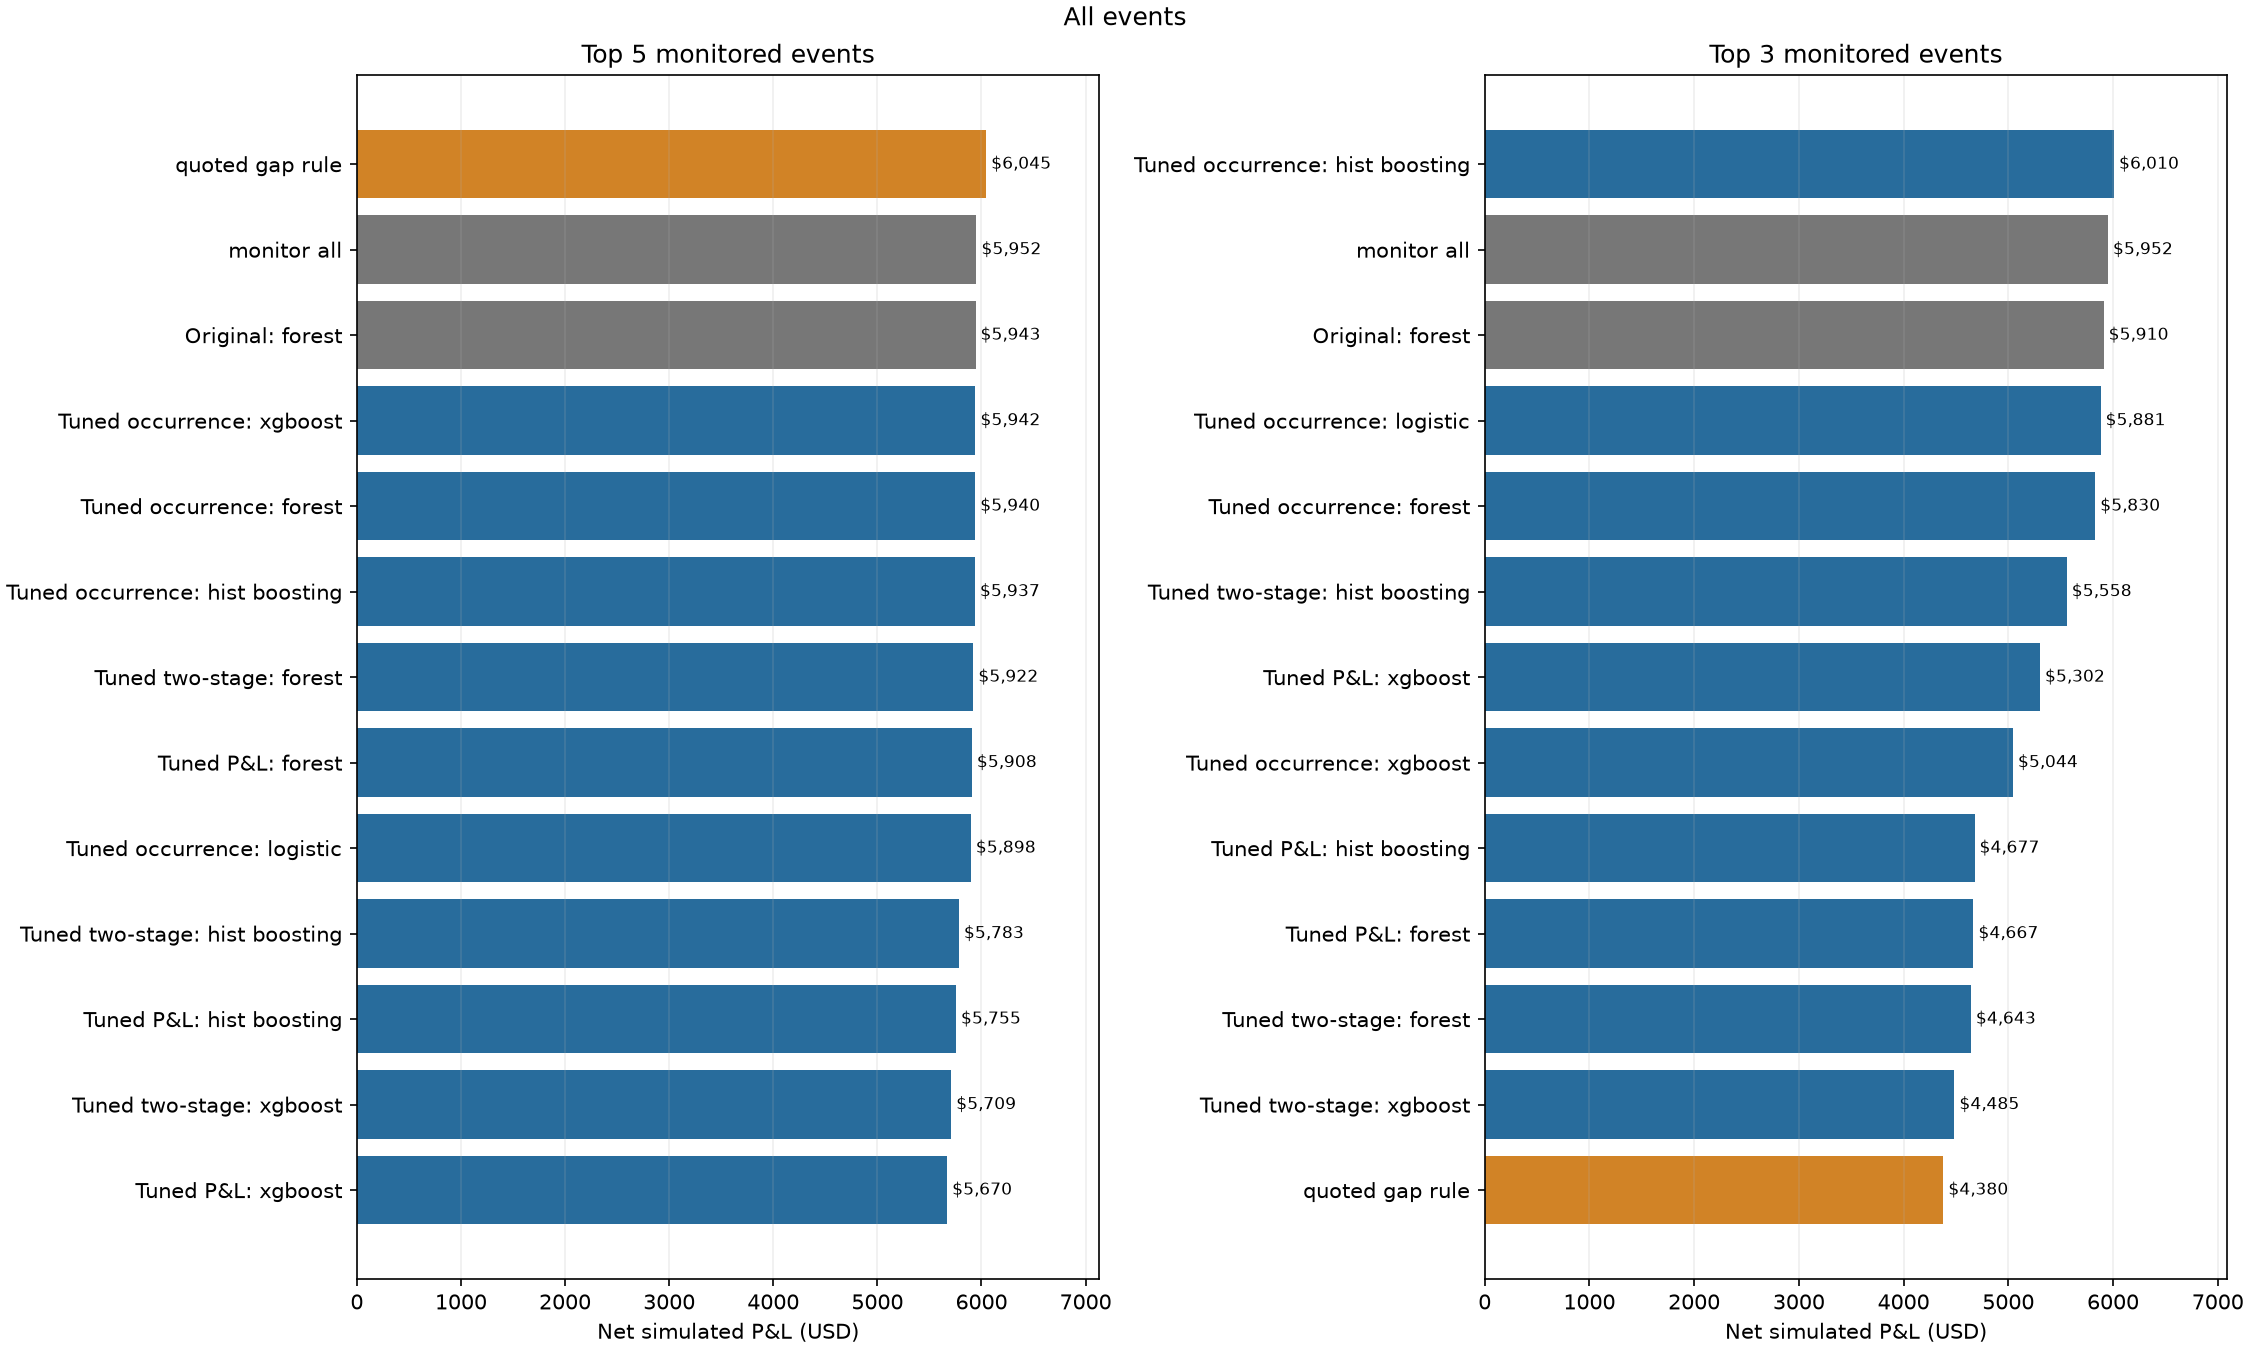

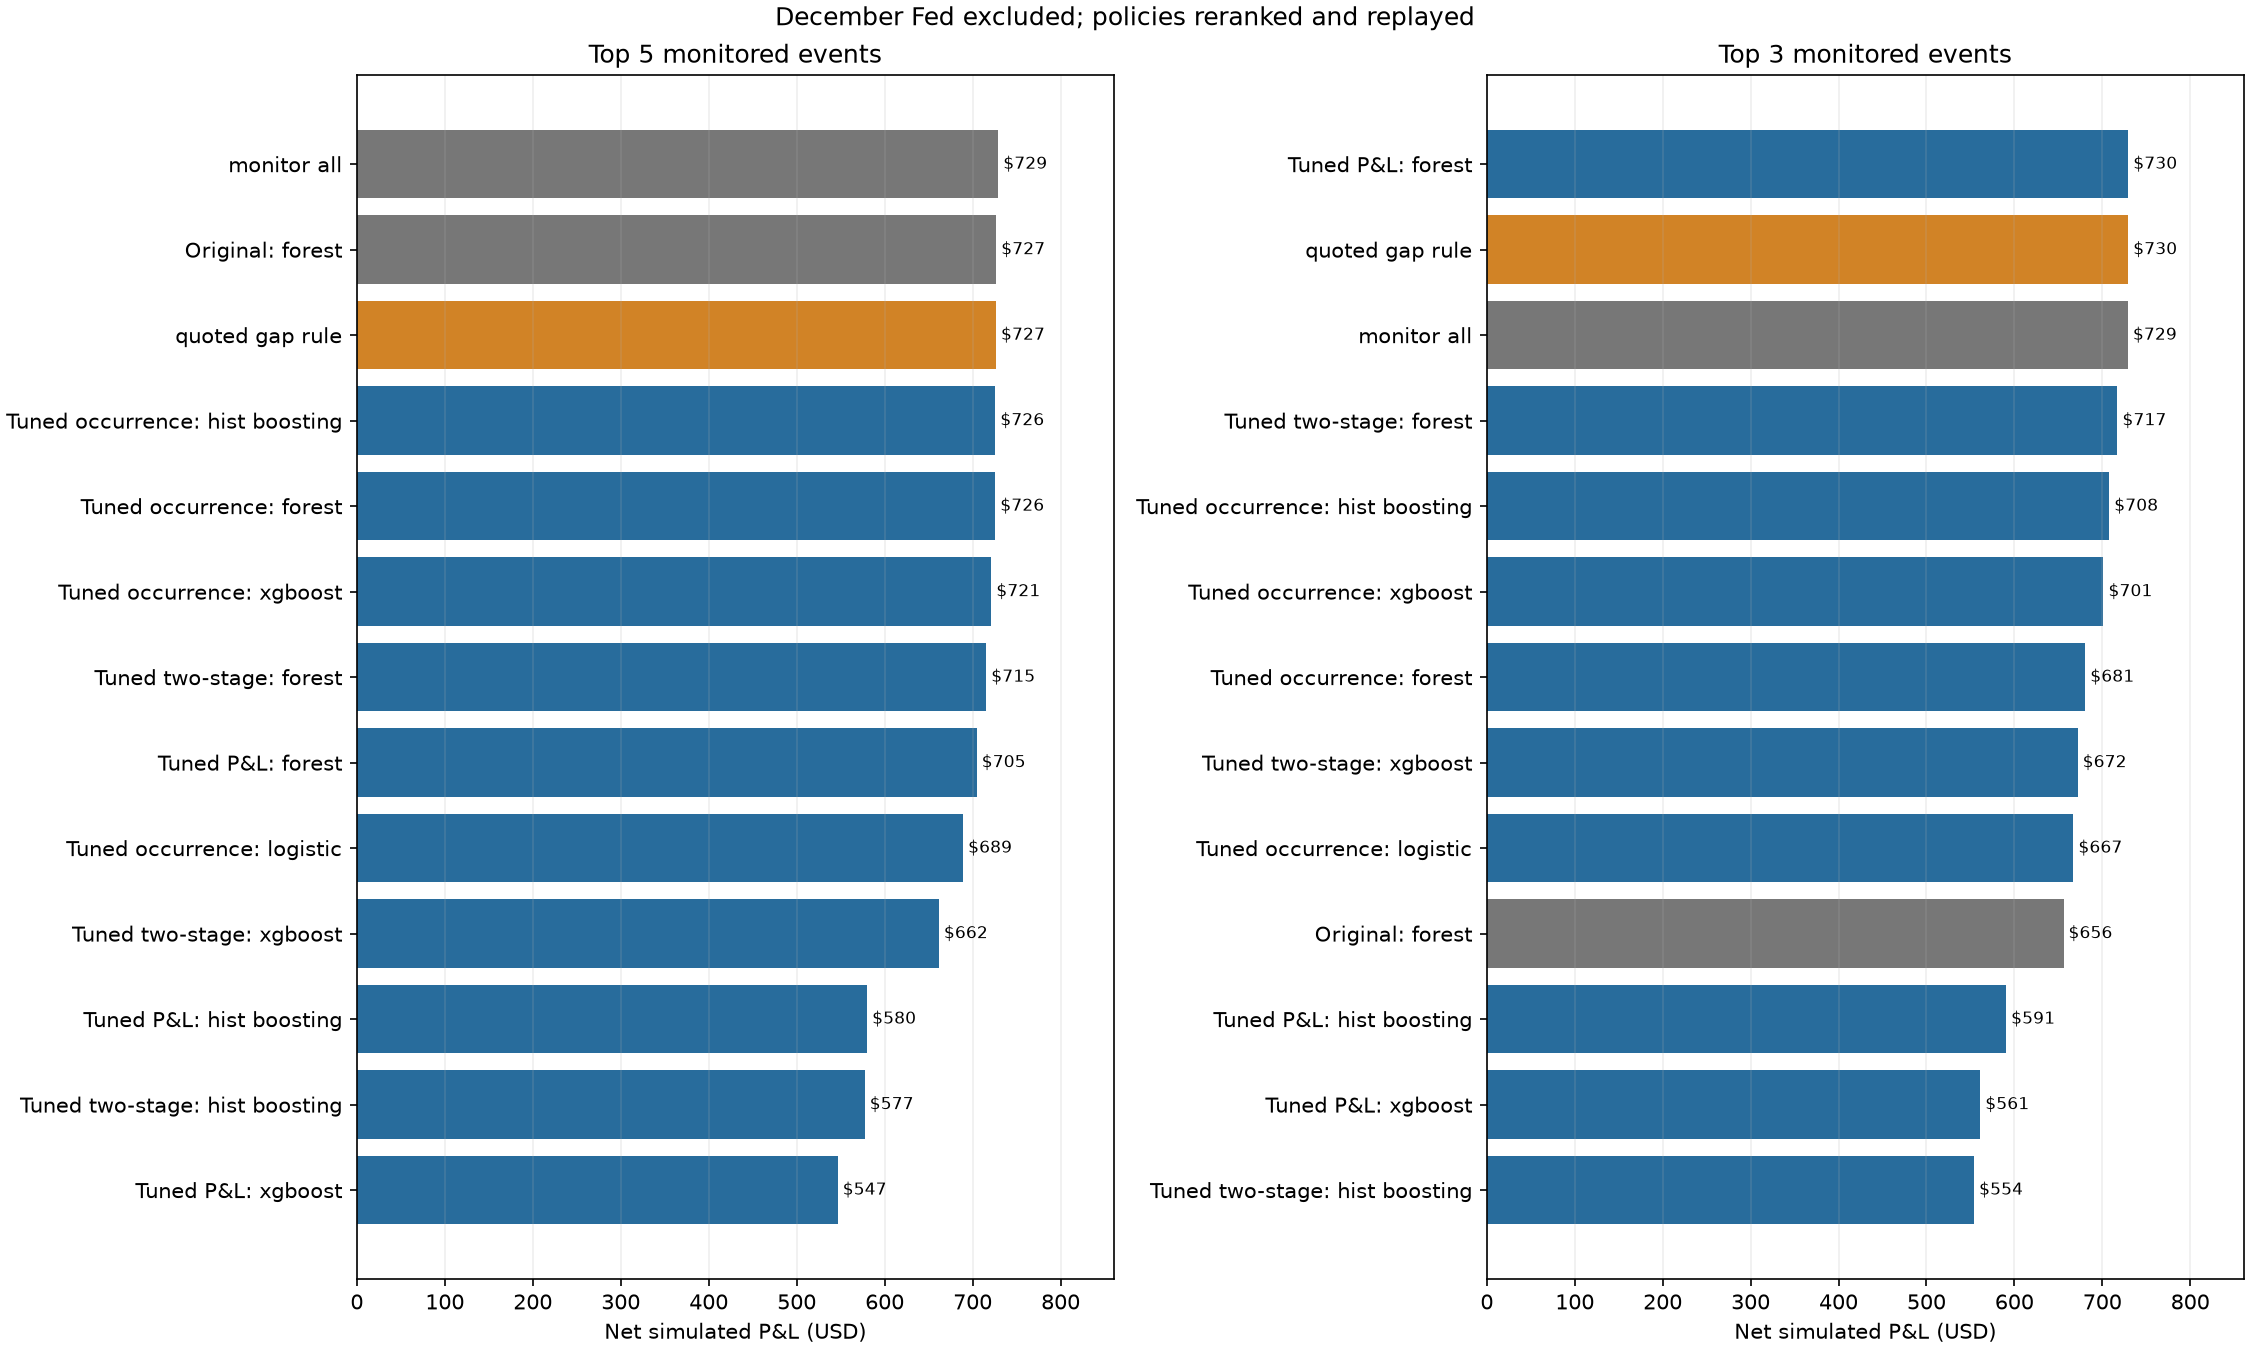

In [4]:
display(Image(filename=str(RUN / 'analysis' / 'all_events.png')))
display(Image(filename=str(RUN / 'analysis' / 'exclude_december_fed.png')))


## Does tuning help the same model family?

Compare tuned sklearn models with their original combined-feature versions. For XGBoost, compare with the first declared fixed configuration, fitted on the same outer training rows. Shared settings for the two-stage gate and amount keep that search bounded; this is not an exhaustive optimisation of either component.

In [5]:
display(changes.sort_values(['scope','budget','difference_usd'], ascending=[True,True,False]).round(4))
folds = pd.read_csv(RUN / 'analysis' / 'fold_results.csv')
display(folds.loc[folds.scope.eq('all_events') & folds.budget.eq(5)]
        .pivot(index='model', columns='fold', values='net_pnl_usd').round(2))


,scope,budget,model,reference,net_pnl_usd,reference_pnl_usd,difference_usd
21,all_events,3,tuned_classifier_logistic,combined_logistic,5881.2488,3749.1751,2132.0738
20,all_events,3,tuned_classifier_boosted_trees,combined_boosted_trees,6009.5969,5203.8316,805.7652
27,all_events,3,tuned_two_stage_boosted_trees,combined_two_stage_boosted_trees,5558.1884,4924.5319,633.6565
24,all_events,3,tuned_regression_boosted_trees,combined_reg_boosted_trees,4677.2073,4367.4028,309.8045
25,all_events,3,tuned_regression_random_forest,combined_reg_random_forest,4667.1448,4592.0516,75.0932
29,all_events,3,tuned_two_stage_xgboost,fixed_two_stage_xgboost,4485.4246,4485.4246,0.0000
22,all_events,3,tuned_classifier_random_forest,combined_random_forest,5830.2061,5910.4299,-80.2238
26,all_events,3,tuned_regression_xgboost,fixed_regression_xgboost,5302.3871,5548.3967,-246.0096
23,all_events,3,tuned_classifier_xgboost,fixed_classifier_xgboost,5044.3050,5815.2928,-770.9879
28,all_events,3,tuned_two_stage_random_forest,combined_two_stage_random_forest,4642.5968,5838.8879,-1196.2911


fold,dec_late,nov_early,nov_late
model,,,
combined_boosted_trees,331.93,4486.53,1110.64
combined_logistic,331.93,4519.27,1074.26
combined_random_forest,331.93,4500.13,1110.64
combined_rank_ensemble,331.93,4502.39,1105.63
combined_reg_boosted_trees,277.79,4012.15,982.06
combined_reg_ensemble,331.93,4437.90,1072.56
combined_reg_random_forest,331.65,4376.02,1086.09
combined_reg_ridge,331.93,4171.85,1082.33
combined_two_stage_boosted_trees,261.81,4484.54,1033.93


## Robustness and uncertainty

The December Fed exclusion asks whether the advantage survives outside the dominant event. The paired intervals resample event families using actual replay returns; they are exploratory, preserve the recorded policy decisions and are not adjusted for searching multiple models. They do not reproduce a new market or re-estimate models in each resample.

In [6]:
display(comparison.loc[comparison.scope.eq('exclude_december_fed'),
                       ['budget','model','net_pnl_usd','partial_pnl_usd','unknown_attempts']]
        .sort_values(['budget','net_pnl_usd'],ascending=[True,False]).round(4))
paired = pd.read_csv(RUN / 'analysis' / 'paired_comparisons.csv')
display(paired.loc[paired.budget.eq(5) & paired.scope.eq('all_events')].round(2))


,budget,model,net_pnl_usd,partial_pnl_usd,unknown_attempts
110,3,tuned_regression_random_forest,729.5617,-81.7270,0
104,3,quoted_gap_rule,729.5014,-118.1639,0
115,3,monitor_all,729.1503,-130.8976,0
113,3,tuned_two_stage_random_forest,717.2388,-128.5528,0
93,3,combined_reg_random_forest,713.5209,-91.0460,0
105,3,tuned_classifier_boosted_trees,707.8945,-93.9328,0
87,3,combined_boosted_trees,707.6641,-93.3628,0
108,3,tuned_classifier_xgboost,701.3382,-93.9328,0
90,3,combined_rank_ensemble,700.3206,-130.6336,0
97,3,combined_two_stage_random_forest,682.7038,-128.0528,0


,scope,model,reference,pnl_difference_usd,lower95,upper95,unknown_attempts,reference_unknown_attempts,families,budget
0,all_events,combined_boosted_trees,quoted_gap_rule,-116.15,-361.91,12.52,0,0,9,5
1,all_events,combined_logistic,quoted_gap_rule,-119.79,-337.87,48.47,0,0,9,5
2,all_events,combined_random_forest,quoted_gap_rule,-102.54,-338.46,29.52,0,0,9,5
3,all_events,combined_rank_ensemble,quoted_gap_rule,-105.30,-330.91,20.14,0,0,9,5
4,all_events,combined_reg_boosted_trees,quoted_gap_rule,-773.26,-2275.27,3.07,0,0,9,5
5,all_events,combined_reg_ensemble,quoted_gap_rule,-202.86,-557.78,19.66,0,0,9,5
6,all_events,combined_reg_random_forest,quoted_gap_rule,-251.49,-757.21,4.99,0,0,9,5
7,all_events,combined_reg_ridge,quoted_gap_rule,-459.15,-1323.28,38.96,0,0,9,5
8,all_events,combined_two_stage_boosted_trees,quoted_gap_rule,-264.98,-720.68,-13.10,0,0,9,5
9,all_events,combined_two_stage_ensemble,quoted_gap_rule,-168.32,-461.61,1.35,0,0,9,5


## Feature analysis and activity probabilities

For each tuned model, permute each feature group between events within the same scan, repeating three times. Positive P&L drops indicate reliance on that group; negative drops mean the perturbation improved the proxy. Groups can overlap, and correlated predictors limit causal interpretation. These are standalone target diagnostics, not replayed strategy profits.

The probability audit concerns the two-stage activity gate. It is distinct from opportunity occurrence and does not establish calibrated probabilities on new events.

In [7]:
importance = pd.read_csv(RUN / 'analysis' / 'feature_importance_by_fold.csv')
display(importance.groupby(['model','group']).pnl_drop.sum().unstack().round(2))
display(pd.read_csv(RUN / 'gate_calibration.csv').round(5))

coefficients = pd.read_csv(RUN / 'analysis' / 'logistic_coefficients.csv')
print('Largest absolute logistic coefficients per fold; scaled inputs, not causal effects')
for fold, rows in coefficients.groupby('fold'):
    print(fold)
    display(rows.assign(magnitude=rows.coefficient.abs()).nlargest(8, 'magnitude')
            [['feature', 'coefficient']].round(4))


group,depth_size,freshness_quality,history,metadata,quoted_gap,spread
model,,,,,,
tuned_classifier_boosted_trees,89.56,15.15,1529.73,35.42,2554.93,17.69
tuned_classifier_logistic,10.40,-27.64,204.90,126.72,490.65,-1.05
tuned_classifier_random_forest,19.94,107.66,1127.80,138.96,1849.41,7.30
tuned_classifier_xgboost,44.97,49.20,1202.78,54.93,3279.64,23.11
tuned_regression_boosted_trees,3.69,1314.36,1160.55,327.27,1856.76,11.57
tuned_regression_random_forest,-13.88,1218.68,995.91,5.12,892.74,-16.29
tuned_regression_xgboost,1.79,722.68,1484.83,27.99,1908.57,-36.43
tuned_two_stage_boosted_trees,67.56,515.70,2549.89,5.54,1919.59,44.34
tuned_two_stage_random_forest,2.98,270.44,1275.21,35.98,3333.41,-2.69


,model,fold,rows,mean_probability,observed_activity,brier
0,fixed_two_stage_xgboost,dec_late,4124,0.01195,0.01188,0.00852
1,fixed_two_stage_xgboost,nov_early,6334,0.02189,0.02605,0.01643
2,fixed_two_stage_xgboost,nov_late,6499,0.02454,0.02631,0.01505
3,tuned_two_stage_boosted_trees,dec_late,4124,0.01259,0.01188,0.00790
4,tuned_two_stage_boosted_trees,nov_early,6334,0.01856,0.02605,0.01580
5,tuned_two_stage_boosted_trees,nov_late,6499,0.02305,0.02631,0.01552
6,tuned_two_stage_random_forest,dec_late,4124,0.01479,0.01188,0.00787
7,tuned_two_stage_random_forest,nov_early,6334,0.02146,0.02605,0.01982
8,tuned_two_stage_random_forest,nov_late,6499,0.02572,0.02631,0.01492
9,tuned_two_stage_xgboost,dec_late,4124,0.01195,0.01188,0.00852


Largest absolute logistic coefficients per fold; scaled inputs, not causal effects
dec_late


,feature,coefficient
176,missingindicator_x_best_quoted_net_usd,-5.2176
163,x_snapshot_lag1_ask_depth_sum,1.9567
167,x_snapshot_lag1_best_quoted_net_usd,1.7214
204,m_topic_elections,1.6415
207,m_topic_sports,-1.5722
168,x_snapshot_change1_best_quoted_net_usd,1.5499
146,x_ask_depth_sum,-1.5208
152,x_snapshot_change1_active_packages,-1.3261


nov_early


,feature,coefficient
33,m_age_days,0.5044
8,x_best_quoted_net_usd,0.4788
27,x_snapshot_lag1_best_quoted_net_usd,0.3909
54,missingindicator_x_snapshot_change1_best_quote...,-0.3093
9,x_size_feasible_package_fraction,0.3055
29,x_snapshot_lag1_size_feasible_package_fraction,0.3043
36,missingindicator_x_best_quoted_net_usd,-0.3026
53,missingindicator_x_snapshot_lag1_best_quoted_n...,-0.3007


nov_late


,feature,coefficient
78,x_best_quoted_net_usd,0.8673
97,x_snapshot_lag1_best_quoted_net_usd,0.5208
103,m_age_days,0.5061
77,x_book_age_max_s,-0.4475
106,missingindicator_x_best_quoted_net_usd,-0.4149
79,x_size_feasible_package_fraction,0.3907
99,x_snapshot_lag1_size_feasible_package_fraction,0.3677
80,x_positive_quoted_net_package_fraction,0.3534


## Interpretation

Read the accompanying report for the measured findings and limitations. Algorithm choice, tuning, objective choice, monitoring budget and event concentration are separate questions. The final model and evaluation procedure must be fixed before the final test is opened. None of these development results demonstrates achievable live profitability.